# Non-adaptive baselines vs the adaptive loop

**Question.** What does a non-adaptive tag (send every frame, compressed) give the server, at what cost, against the adaptive loop?

**Setup.** The switch stream (room A `training` → Mall tile → room A rearranged `training_seats`, `test2`; every 2nd PIROPO frame, every Mall frame), one pass. The server's answer is FCOS on what it received (`teacher_eval.py --input ...`), thresholded at the midpoint of its label-free cutoffs. Inputs: the full 160×120 frame (19,200 B), JPEG 160×120 at quality 88 and 50 (scan bytes only, header shared), and block-mean thumbnails 80×60 (4,800 B) and 40×30 (1,200 B).

Adaptive points: `online_pixels_cal` / `online_cells_cal` with tiered checks and FCOS as teacher (`tiered_checks.py`), full frames sent raw or as JPEG q88 (`fcos_jpeg`). All points score the same frames. The hollow adaptive markers are the second half of each room (after the loop has had time to settle).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('..').resolve()))
sys.path.insert(0, str(Path('.').resolve()))
from semwisp import piropo
from semwisp.metrics import summary
from tiered_checks import fcos_cutoffs

TEA = piropo.REPO / 'results' / 'teachers'
TC = piropo.REPO / 'results' / 'tiered_checks'
SEQ = {'training': 'room A (training)', 'mall_tile': 'room B (mall tile)',
       'training_seats': 'room A, rearranged', 'test2': 'room A, rearranged (test2)'}
pos, neg = fcos_cutoffs(); thr = (pos + neg) / 2

def ba(d):
    return float((d.answer[d.label == 1].mean() + (1 - d.answer[d.label == 0]).mean()) / 2)

# labels per query come from an adaptive run (same frames, same order)
z = np.load(TC / 'switch_fcos_online_pixels_cal_tiered_b200.npz')
lab = pd.DataFrame({'seq': z['seq'], 't': z['t'], 'label': z['label']})
INPUTS = {'full frame': 'fcos_r50@480_s2', 'JPEG q88': 'fcos_r50@480_jpeg160x120q88_s2',
          'JPEG q50': 'fcos_r50@480_jpeg160x120q50_s2', 'thumbnail 80×60': 'fcos_r50@480_thumb80x60_s2',
          'thumbnail 40×30': 'fcos_r50@480_thumb40x30_s2'}
rows, per_room = [], []
for name, folder in INPUTS.items():
    parts = []
    for f, s in SEQ.items():
        r = np.load(TEA / folder / f'{f}.npz')
        by = r['bytes'] if 'bytes' in r.files else np.full(len(r['t']), 19200)
        parts.append(pd.DataFrame({'seq': s, 't': r['t'], 'score': r['score'], 'bytes': by}))
    d = lab.merge(pd.concat(parts), on=['seq', 't'], how='left', validate='1:1')
    assert d.score.notna().all()
    d['answer'] = (d.score >= thr).astype(float)
    rows.append(dict(method=name, adaptive=False, balanced_acc=ba(d), bytes_per_query=d.bytes.mean()))
    for s, g in d.groupby('seq', sort=False):
        per_room.append(dict(method=name, room=s, balanced_acc=ba(g), bytes_per_query=g.bytes.mean()))

ADAPT = {'adaptive, raw full frames': 'switch_fcos_online_pixels_cal_tiered_b200',
         'adaptive, JPEG full frames': 'switch_fcos_jpeg_online_pixels_cal_tiered_b200',
         'adaptive cells, raw full frames': 'switch_fcos_online_cells_cal_tiered_b200',
         'adaptive cells, JPEG full frames': 'switch_fcos_jpeg_online_cells_cal_tiered_b200'}
settled = {}
for name, run in ADAPT.items():
    z = np.load(TC / f'{run}.npz'); n = len(z['label'])
    d = pd.DataFrame({k: z[k] for k in z.files if k != 'meta' and z[k].shape == (n,)})
    s = summary(d)
    rows.append(dict(method=name, adaptive=True, balanced_acc=s['balanced_accuracy'], bytes_per_query=s['up_bytes_per_query']))
    late = pd.concat([g.iloc[len(g) // 2:] for _, g in d.groupby('seq', sort=False)])
    settled[name] = (ba(late), late.up_bytes.mean())
    for s_, g in d.groupby('seq', sort=False):
        m = summary(g)
        per_room.append(dict(method=name, room=s_, balanced_acc=m['balanced_accuracy'], bytes_per_query=m['up_bytes_per_query']))
T = pd.DataFrame(rows)
T['settled_acc'] = T.method.map(lambda m: settled.get(m, (np.nan,))[0])
T['settled_bytes'] = T.method.map(lambda m: settled.get(m, (np.nan, np.nan))[1])
T.style.format({'balanced_acc': '{:.3f}', 'bytes_per_query': '{:,.0f}', 'settled_acc': '{:.3f}', 'settled_bytes': '{:,.0f}'}, na_rep='')

,method,adaptive,balanced_acc,bytes_per_query,settled_acc,settled_bytes
0,full frame,False,0.924,"19,200",,
1,JPEG q88,False,0.921,"5,034",,
2,JPEG q50,False,0.851,"2,331",,
3,thumbnail 80×60,False,0.788,"4,800",,
4,thumbnail 40×30,False,0.563,"1,200",,
5,"adaptive, raw full frames",True,0.865,"4,863",0.847,"1,689"
6,"adaptive, JPEG full frames",True,0.882,"1,302",0.879,290
7,"adaptive cells, raw full frames",True,0.884,"4,351",0.872,"1,103"
8,"adaptive cells, JPEG full frames",True,0.884,"1,442",0.886,449


In [2]:
(pd.DataFrame(per_room).pivot_table(index='method', columns='room', values=['balanced_acc', 'bytes_per_query'], sort=False)
   .style.format('{:.3f}', subset='balanced_acc').format('{:,.0f}', subset='bytes_per_query'))

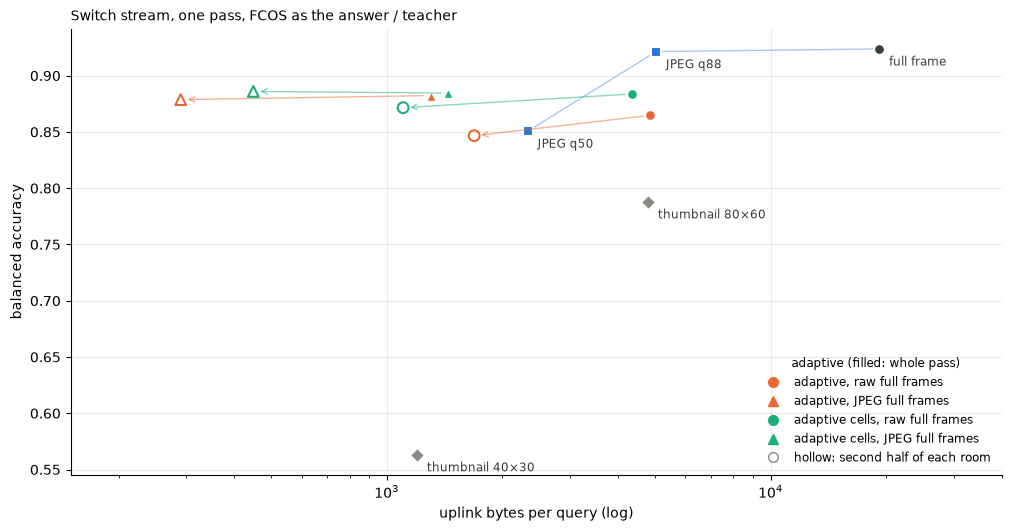

In [3]:
from matplotlib.lines import Line2D
BLUE, ORANGE, AQUA, GRAY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984', '#3d3d3a'
style = {'full frame': (INK, 'o'), 'JPEG q88': (BLUE, 's'), 'JPEG q50': (BLUE, 's'),
         'thumbnail 80×60': (GRAY, 'D'), 'thumbnail 40×30': (GRAY, 'D'),
         'adaptive, raw full frames': (ORANGE, 'o'), 'adaptive, JPEG full frames': (ORANGE, '^'),
         'adaptive cells, raw full frames': (AQUA, 'o'), 'adaptive cells, JPEG full frames': (AQUA, '^')}
fig, ax = plt.subplots(figsize=(10, 5.2), constrained_layout=True)
jp = T[T.method.isin(['JPEG q50', 'JPEG q88', 'full frame'])].sort_values('bytes_per_query')
ax.plot(jp.bytes_per_query, jp.balanced_acc, color=BLUE, lw=1, alpha=0.4, zorder=1)
handles = []
for _, r in T.iterrows():
    c, mk = style[r.method]
    ax.scatter(r.bytes_per_query, r.balanced_acc, s=60, color=c, marker=mk, edgecolor='white', linewidth=1.5, zorder=3)
    if r.adaptive:
        ax.scatter(r.settled_bytes, r.settled_acc, s=60, facecolor='none', edgecolor=c, marker=mk, linewidth=1.5, zorder=3)
        ax.annotate('', (r.settled_bytes, r.settled_acc), (r.bytes_per_query, r.balanced_acc),
                    arrowprops=dict(arrowstyle='->', color=c, lw=1, alpha=0.5, shrinkA=5, shrinkB=5))
        handles.append(Line2D([], [], color=c, marker=mk, ls='', ms=7, label=r.method))
    else:
        ax.annotate(r.method, (r.bytes_per_query, r.balanced_acc), xytext=(7, -12), textcoords='offset points', fontsize=8.5, color=INK)
handles.append(Line2D([], [], color=GRAY, marker='o', ls='', ms=7, mfc='none', label='hollow: second half of each room'))
ax.legend(handles=handles, loc='lower right', frameon=False, fontsize=8.5, title='adaptive (filled: whole pass)', title_fontsize=8.5)
ax.set_xscale('log'); ax.set_xlim(150, 40000)
ax.set_xlabel('uplink bytes per query (log)'); ax.set_ylabel('balanced accuracy')
ax.set_title('Switch stream, one pass, FCOS as the answer / teacher', loc='left', fontsize=10)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(alpha=0.25)
plt.show()

## Every method side by side

Each row is one method. Left: balanced accuracy, right: uplink bytes per query (log). Colored markers are the four parts of the stream; the black bar is the whole pass. The dashed line in each panel marks JPEG q88, the best non-adaptive option.

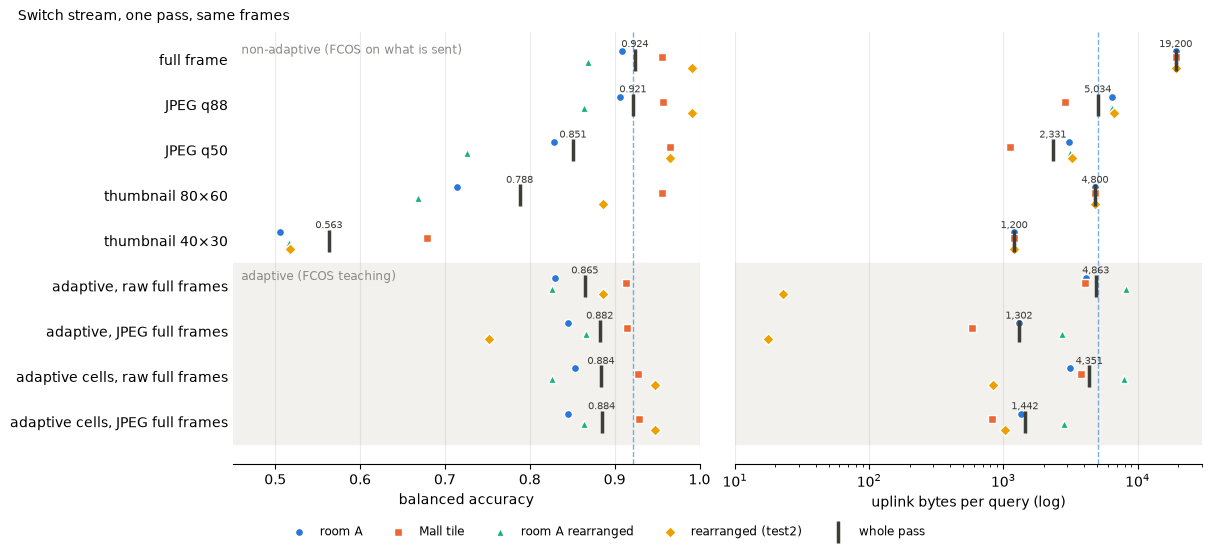

In [4]:
import matplotlib.patches as mpatches
R = pd.DataFrame(per_room)
ROOMS = {'room A (training)': ('room A', '#2a78d6', 'o'), 'room B (mall tile)': ('Mall tile', '#eb6834', 's'),
         'room A, rearranged': ('room A rearranged', '#1baf7a', '^'),
         'room A, rearranged (test2)': ('rearranged (test2)', '#eda100', 'D')}
order = list(T.method)
y = {m: i for i, m in enumerate(order)}
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True, constrained_layout=True)
for ax, col in zip(axs, ['balanced_acc', 'bytes_per_query']):
    nonad = (~T.adaptive).sum()
    ax.axhspan(nonad - 0.5, len(order) - 0.5, color='#f2f1ed', zorder=0)
    for room, (lab, c, mk) in ROOMS.items():
        d = R[R.room == room]
        off = (list(ROOMS).index(room) - 1.5) * 0.12
        ax.scatter(d[col], d.method.map(y) + off, color=c, marker=mk, s=34, edgecolor='white', linewidth=1, zorder=3, label=lab)
    ax.scatter(T[col], T.method.map(y), marker='|', s=260, color=INK, linewidth=2.5, zorder=4, label='whole pass')
    ref = T.loc[T.method == 'JPEG q88', col].item()
    ax.axvline(ref, color=BLUE, lw=1, ls='--', alpha=0.6, zorder=1)
    for _, r in T.iterrows():
        txt = f'{r[col]:.3f}' if col == 'balanced_acc' else f'{r[col]:,.0f}'
        ax.annotate(txt, (r[col], y[r.method]), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=7.5, color=INK)
    for s_ in ('top', 'right', 'left'): ax.spines[s_].set_visible(False)
    ax.tick_params(axis='y', length=0); ax.grid(axis='x', alpha=0.25)
axs[0].set_xlabel('balanced accuracy'); axs[0].set_xlim(0.45, 1.0)
axs[1].set_xlabel('uplink bytes per query (log)'); axs[1].set_xscale('log'); axs[1].set_xlim(10, 30000)
axs[0].set_yticks(range(len(order)), order); axs[0].invert_yaxis()
axs[0].text(0.46, (~T.adaptive).sum() - 0.35, 'adaptive (FCOS teaching)', fontsize=8.5, color=GRAY, va='top')
axs[0].text(0.46, -0.35, 'non-adaptive (FCOS on what is sent)', fontsize=8.5, color=GRAY, va='top')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='outside lower center', ncol=5, frameon=False, fontsize=8.5)
fig.suptitle('Switch stream, one pass, same frames', x=0.01, ha='left', fontsize=10)
out = piropo.REPO / 'results' / 'baselines'; out.mkdir(exist_ok=True)
fig.savefig(out / 'methods_compared.png', dpi=200)
plt.show()

## Findings

* **Non-adaptive: only JPEG at high quality keeps full-frame accuracy.** JPEG q88 0.921 at 5,034 B (full frame 0.924 at 19,200). Below that it falls off fast: JPEG q50 0.851 at 2,331 B, thumbnails 80×60 0.788 at 4,800 B and 40×30 0.563 (near chance) at 1,200 B. In PIROPO a person is a few pixels wide after downsampling; on the Mall tile (larger people) JPEG q50 and 80×60 still match the full frame.
* **The adaptive loop with JPEG full frames is better than JPEG q50 at fewer bytes**: 0.882 at 1,302 B (pixels) and 0.884 at 1,442 B (cells), over the whole first pass including learning. In the second half of each room it sends 290–450 B/query at 0.88–0.89. So below ~5 kB per query the loop beats every non-adaptive option we tried; it reaches JPEG q50's accuracy at 8× fewer bytes once settled.
* **It does not reach full-frame accuracy**: ~0.04 below JPEG q88 / full frames. Above ~5 kB per query, JPEG q88 is the better choice. Closing that gap (rather than cutting bytes further) is now the main open problem for a first pass.
* JPEG on the full frames is a pure add-on: it cut the loop's bytes ~3.5× (4,863 → 1,302) without costing accuracy. The two mechanisms (generic compression of the learning traffic, task-focused code for the answers) are still separate.